In [1]:
import pandas as pd

# Path to the CSV file (update this to your actual file path)
file_path = "annotated_name_string.csv"

# Read the CSV file using UTF-8 encoding
df = pd.read_csv(file_path, encoding="utf-8")

# Preview the first few rows
print(df.head())

# Check the shape of the DataFrame (should be 1055 rows and 2 columns)
print(df.shape)

                                 Name_string  \
0                Lake Macquarie City Council   
1             Sri Devraj Urs Medical College   
2  Swedish Foundation for Strategic Research   
3                  Korea Research Foundation   
4                Florida Atlantic University   

                              Annotated_name  
0                Lake Macquarie City Council  
1            Sri Devaraj Urs Medical College  
2  Swedish Foundation for Strategic Research  
3      National Research Foundation of Korea  
4                Florida Atlantic University  
(1055, 2)


In [2]:
# Function to combine Name_string and Annotated_name within each group

def build_org_list(group):
    
    # Collect values from both columns
    name_strings = group["Name_string"].dropna().tolist()
    annotated_names = group["Annotated_name"].dropna().tolist()
    
    # Combine and remove duplicates while preserving order
    combined = list(dict.fromkeys(name_strings + annotated_names))
    
    return combined

In [3]:
# Group by Annotated_name and build the OrgName list
grouped = df.groupby("Annotated_name").apply(build_org_list).reset_index()

# Rename columns
grouped.columns = ["Annotated_name", "OrgName"]

# Create ClusterID starting from 10000001
grouped["ClusterID"] = range(10000001, 10000001 + len(grouped))

# Reorder columns
grouped = grouped[["ClusterID", "Annotated_name", "OrgName"]]

# Preview result
print(grouped.head())

   ClusterID                                     Annotated_name  \
0   10000001  2021 Tianjin Postgraduate Research and Innovat...   
1   10000002                                    3IA Côte d'Azur   
2   10000003  5511 Science and Technology Innovation Talent ...   
3   10000004                            7th Framework Programme   
4   10000005                    ACTION FOR AIDS (AfA SINGAPORE)   

                                             OrgName  
0  [2021 Tianjin Postgraduate Research and Innova...  
1                 [3IA Côte d’Azur, 3IA Côte d'Azur]  
2  [5511 Science and Technology Innovation Talent...  
3  [FP7 European Commission 7th Framework, 7th Fr...  
4  [Action for AIDS, ACTION FOR AIDS (AfA SINGAPO...  


In [4]:
# Number of rows (i.e., number of clusters)
print(grouped.shape[0])

990


In [5]:
# Count number of elements in each OrgName list
grouped["OrgName_count"] = grouped["OrgName"].apply(len)

print(grouped[["ClusterID", "OrgName_count"]].head(20))

    ClusterID  OrgName_count
0    10000001              1
1    10000002              2
2    10000003              1
3    10000004              2
4    10000005              2
5    10000006              2
6    10000007              2
7    10000008              1
8    10000009              2
9    10000010              1
10   10000011              1
11   10000012              1
12   10000013              2
13   10000014              2
14   10000015              1
15   10000016              1
16   10000017              2
17   10000018              3
18   10000019              3
19   10000020              2


In [6]:
# Summary statistics for OrgName list sizes
print(grouped["OrgName_count"].describe())

count    990.000000
mean       1.438384
std        0.716511
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       13.000000
Name: OrgName_count, dtype: float64


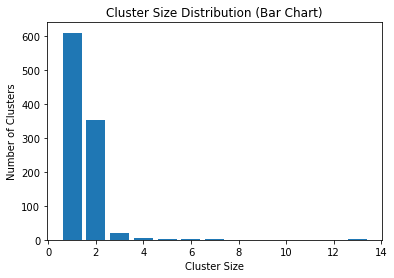

In [7]:
import matplotlib.pyplot as plt

# Count how many clusters exist for each size
size_counts = grouped["OrgName_count"].value_counts().sort_index()

# Plot as bar chart
plt.figure()
plt.bar(size_counts.index, size_counts.values)

# Labels and title
plt.xlabel("Cluster Size")
plt.ylabel("Number of Clusters")
plt.title("Cluster Size Distribution (Bar Chart)")

plt.show()

In [8]:
# Step 1. Explode OrgName list into row-level data
exploded = grouped.explode("OrgName").reset_index(drop=True)

# Step 2. Assign InstanceID starting from 100000001
exploded["InstanceID"] = range(100000001, 100000001 + len(exploded))

# Step 3. Convert InstanceID to string (for joining later)
exploded["InstanceID"] = exploded["InstanceID"].astype(str)

# Step 4. Group back by ClusterID and join InstanceIDs with "|"
instance_map = (
    exploded.groupby("ClusterID")["InstanceID"]
    .apply(lambda x: "|".join(x))
    .reset_index()
)

# Step 5. Merge back to original grouped DataFrame
grouped = grouped.merge(instance_map, on="ClusterID", how="left")

# Rename column for clarity
grouped = grouped.rename(columns={"InstanceID": "InstanceIDs"})

# Preview
print(grouped.head())

   ClusterID                                     Annotated_name  \
0   10000001  2021 Tianjin Postgraduate Research and Innovat...   
1   10000002                                    3IA Côte d'Azur   
2   10000003  5511 Science and Technology Innovation Talent ...   
3   10000004                            7th Framework Programme   
4   10000005                    ACTION FOR AIDS (AfA SINGAPORE)   

                                             OrgName  OrgName_count  \
0  [2021 Tianjin Postgraduate Research and Innova...              1   
1                 [3IA Côte d’Azur, 3IA Côte d'Azur]              2   
2  [5511 Science and Technology Innovation Talent...              1   
3  [FP7 European Commission 7th Framework, 7th Fr...              2   
4  [Action for AIDS, ACTION FOR AIDS (AfA SINGAPO...              2   

           InstanceIDs  
0            100000001  
1  100000002|100000003  
2            100000004  
3  100000005|100000006  
4  100000007|100000008  


In [9]:
# Save only ClusterID and InstanceIDs as a tab-separated .txt file
grouped[["ClusterID", "InstanceIDs"]].to_csv(
    "clusters.txt",      # Output file name
    sep="\t",          # Use tab as delimiter
    index=False,       # Do not write row index
    header=False,      # Do not include column names
    encoding="utf-8"   # Ensure proper encoding
)

In [10]:
# Count total number of elements across all OrgName lists
total_count = grouped["OrgName"].apply(len).sum()

print("Total number of OrgName elements:", total_count)

Total number of OrgName elements: 1424


In [11]:
# Select only the required columns
output_df = exploded[["InstanceID", "OrgName"]]

# Save as tab-separated text file (no header, no index)
output_df.to_csv(
    "instance_orgname.txt",
    sep="\t",          # Use tab as delimiter
    index=False,       # Do not write row index
    header=False,      # Do not write column names
    encoding="utf-8"  # Ensure proper encoding for non-English text
)